Mup Lab1 

In [8]:
!pip install --break-system-packages PyMPDATA numba==0.61.2



Defaulting to user installation because normal site-packages is not writeable


In [2]:
import PyMPDATA 

print(PyMPDATA.__file__)

/home/stud2022/2byrski/.local/lib/python3.13/site-packages/PyMPDATA/__init__.py


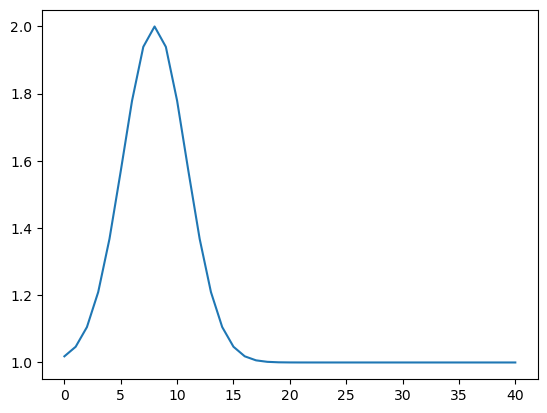

In [19]:
import numpy
import matplotlib.pyplot as plt
x=numpy.linspace(-2,8,41)
y=numpy.exp(-x*x)+1
plt.plot(y)

In [20]:

from PyMPDATA import ScalarField, VectorField, Options, Stepper, Solver, boundary_conditions

common={
   'halo':(options:=Options(nonoscillatory=True)).n_halo,
   'boundary_conditions':(boundary_conditions.Periodic(),)
    
}
advector=VectorField(**common,data=(numpy.full(x.size+1,0.25),))
advectee=ScalarField(**common,data=y)
solver=Solver(advectee=advectee,advector=advector,stepper=Stepper(n_dims=1,options=options))
solver.advance(n_steps=100)

8895.88

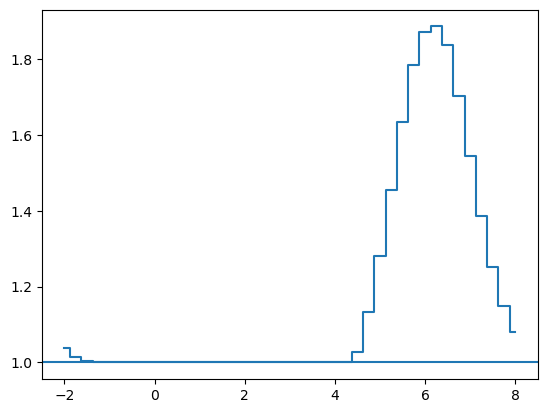

In [21]:
plt.step(x,solver.advectee.get(), where='mid')
plt.axhline(1)